### 1. Import libraries

In [1]:
import time
import numpy as np
import pandas as pd
import seaborn as sns
import plotly.express as px
import matplotlib.pyplot as plt
from collections import Counter
import plotly.graph_objects as go
from sklearn.linear_model import Lasso
from scipy.spatial.distance import cdist
from plotly.subplots import make_subplots
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, silhouette_score
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.preprocessing import LabelEncoder, MinMaxScaler

from model import myKMeans, MyDBSCAN

### Dataset and preprocessing

In [2]:
df_raw = pd.read_json('data/data.json')

In [3]:
df_raw.head(2)

,bathrooms,bedrooms,building_id,created,description,display_address,features,latitude,listing_id,longitude,manager_id,photos,price,street_address,interest_level
4,1.0,1,8579a0b0d54db803821a35a4a615e97a,2016-06-16 05:55:27,Spacious 1 Bedroom 1 Bathroom in Williamsburg!...,145 Borinquen Place,"[Dining Room, Pre-War, Laundry in Building, Di...",40.7108,7170325,-73.9539,a10db4590843d78c784171a107bdacb4,[https://photos.renthop.com/2/7170325_3bb5ac84...,2400,145 Borinquen Place,medium
6,1.0,2,b8e75fc949a6cd8225b455648a951712,2016-06-01 05:44:33,BRAND NEW GUT RENOVATED TRUE 2 BEDROOMFind you...,East 44th,"[Doorman, Elevator, Laundry in Building, Dishw...",40.7513,7092344,-73.9722,955db33477af4f40004820b4aed804a0,[https://photos.renthop.com/2/7092344_7663c19a...,3800,230 East 44th,low


In [4]:
df = df_raw[['bathrooms', 'bedrooms', 'price', 'features', 'created', 'latitude', 'longitude', 'interest_level']].copy().reset_index(drop=True)
df['price'] = pd.to_numeric(df['price'], errors='coerce')
df['price'].dropna(inplace=True)
df = df.set_index(['created'])
df.sort_index(inplace=True)

In [5]:
df.head()

,bathrooms,bedrooms,price,features,latitude,longitude,interest_level
created,,,,,,,
2016-04-01 22:12:41,1.0,1,3195,"[Doorman, Elevator, Laundry In Building]",40.7302,-73.9924,high
2016-04-01 22:56:00,1.0,0,2000,"[Cats Allowed, Dogs Allowed, No Fee, Laundry I...",40.7576,-73.9677,medium
2016-04-01 22:57:15,2.0,3,5850,"[Common Outdoor Space, Cats Allowed, Private O...",40.7388,-73.9851,high
2016-04-01 23:26:07,1.0,1,2745,"[Common Outdoor Space, Cats Allowed, Dogs Allo...",40.7939,-73.9738,medium
2016-04-02 00:48:13,1.0,1,2400,"[Cats Allowed, Dogs Allowed, Doorman, Elevator...",40.7784,-73.9491,medium


In [6]:
# All in one cell

target = 'price'

#Removing the outliers(from the target)
low_limit = np.percentile(df[target], 1)
high_limit = np.percentile(df[target], 99)
df_clean = df[(df[target] >= low_limit) & (df[target] <= high_limit)].copy()


#Creating sparse matrix features
all_features_list = []
for row in df_clean['features']:
    all_features_list.extend(row)

feature_list = []
for st in all_features_list:
    st = st.replace(" ", "").replace("[", "").replace("]", "").replace("'", "").replace('"', '')
    feature_list.append(st)

c = Counter(feature_list)
most_common_features = [item[0] for item in c.most_common(20)]

def doesithave(li, most):
    if most in li:
        return 1
    return 0

for most in most_common_features:
    df_clean[most] = df_clean['features'].apply(lambda x: doesithave(x, most))
df_clean.drop(['features'], axis=1, inplace=True)


#Encoding the column 'interest_level'
le = LabelEncoder()
df_clean['interest_level'] = le.fit_transform(df_clean['interest_level'])

In [7]:
X = pd.DataFrame(df_clean.drop(['price'], axis=1))
X.index = pd.to_datetime(X.index)
X.sort_index(inplace=True)
y = pd.Series(df_clean['price'])
y.sort_index(inplace=True)
X_back = pd.DataFrame(X)

In [8]:
X.head(3)

,bathrooms,bedrooms,latitude,longitude,interest_level,Elevator,HardwoodFloors,CatsAllowed,DogsAllowed,Doorman,...,LaundryinUnit,RoofDeck,OutdoorSpace,DiningRoom,HighSpeedInternet,Balcony,SwimmingPool,LaundryInBuilding,NewConstruction,Terrace
created,,,,,,,,,,,,,,,,,,,,,
2016-04-01 22:12:41,1.0,1,40.7302,-73.9924,0,1,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
2016-04-01 22:56:00,1.0,0,40.7576,-73.9677,2,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2016-04-01 22:57:15,2.0,3,40.7388,-73.9851,0,1,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0


In [9]:
X.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 48379 entries, 2016-04-01 22:12:41 to 2016-06-29 21:41:47
Data columns (total 25 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   bathrooms          48379 non-null  float64
 1   bedrooms           48379 non-null  int64  
 2   latitude           48379 non-null  float64
 3   longitude          48379 non-null  float64
 4   interest_level     48379 non-null  int64  
 5   Elevator           48379 non-null  int64  
 6   HardwoodFloors     48379 non-null  int64  
 7   CatsAllowed        48379 non-null  int64  
 8   DogsAllowed        48379 non-null  int64  
 9   Doorman            48379 non-null  int64  
 10  Dishwasher         48379 non-null  int64  
 11  NoFee              48379 non-null  int64  
 12  LaundryinBuilding  48379 non-null  int64  
 13  FitnessCenter      48379 non-null  int64  
 14  Pre-War            48379 non-null  int64  
 15  LaundryinUnit      48379 non-null  int64  
 16

In [10]:
y.info()

<class 'pandas.Series'>
Index: 48379 entries, 2016-04-01 22:12:41 to 2016-06-29 21:41:47
Series name: price
Non-Null Count  Dtype
--------------  -----
48379 non-null  int64
dtypes: int64(1)
memory usage: 1.7+ MB


## K-means algorithm.

### Fitting the model with 30 clusters on 'longitude' and 'latitude' features, make prediction for training and test samples.


In [11]:
X_train_ll, X_test_ll, _, _ = train_test_split(X[['longitude', 'latitude']], y, test_size=0.3, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [12]:
%%time
kmeans = myKMeans(n_clusters=30)
kmeans.fit(X_train_ll)

Converged at iteration 29
CPU times: user 1min 17s, sys: 19 ms, total: 1min 17s
Wall time: 1min 18s


In [13]:
%%time
train_pred = kmeans.predict(X_train_ll)
test_pred = kmeans.predict(X_test_ll)

CPU times: user 2.67 s, sys: 3.96 ms, total: 2.67 s
Wall time: 2.69 s


### Silhouette score and Distortion.

In [14]:
results = pd.DataFrame(columns=['model', 'Silhouette/train', 'Silhouette/test', 'Distortion/train', 'Distortion/test'])

In [15]:
%%time
sil_train = silhouette_score(X_train_ll, train_pred)
sil_test = silhouette_score(X_test_ll, test_pred)
dist_train = sum(np.min(cdist(X_train_ll, kmeans.cluster_centers_, 'euclidean'), axis=1)**2) / X_train_ll.shape[0]
dist_test = sum(np.min(cdist(X_test_ll, kmeans.cluster_centers_, 'euclidean'), axis=1)**2) / X_test_ll.shape[0]
results.loc[len(results)] = ['MyKMeans', sil_train, sil_test, dist_train, dist_test]

print("Silhouette Score:")
print(f"train: {sil_train}")
print(f"test: {sil_test}")
print("\nDistortion:")
print(f"train: {dist_train}")
print(f"test: {dist_test}")

Silhouette Score:
train: 0.4101955590483816
test: 0.41203179921224914

Distortion:
train: 0.0008909101040650224
test: 0.0006756817063656294
CPU times: user 49.3 s, sys: 50.5 s, total: 1min 39s
Wall time: 12.6 s


<h4>
For Silhouette Score the best value is 1 and the worst value is -1.<br>
For Distortion, a lower distortion value indicates better clustering.
</h4>

### Visualizing the results

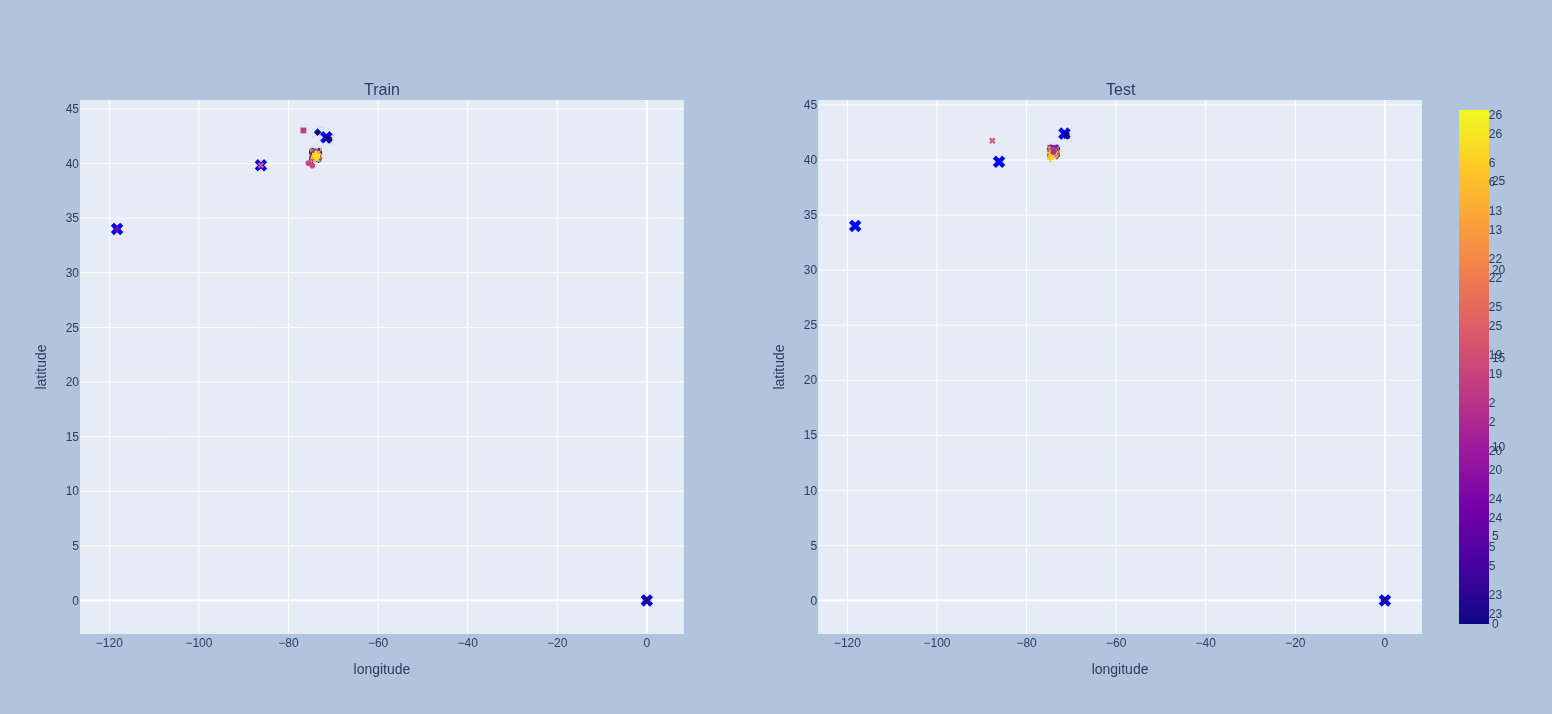

In [16]:
train_labels = kmeans.predict(X_train_ll)
test_labels = kmeans.predict(X_test_ll)
centroids = kmeans.cluster_centers_

fig = make_subplots(subplot_titles=("Train", "Test"), rows=1, cols=2, specs=[[{"type": "scatter"}, {"type": "scatter"}]])
fig1 = px.scatter(X_train_ll, x='longitude', y='latitude', color=train_labels, symbol=train_labels)
fig2 = px.scatter(X_test_ll, x='longitude', y='latitude', color=test_labels, symbol=test_labels)

for i in [1, 2]:
  fig.update_xaxes(title_text="longitude", row = 1, col = i)
  fig.update_yaxes(title_text="latitude", row = 1, col = i)

for trace in fig1.data:
  fig.add_trace(trace, row=1, col=1)
for trace in fig2.data:
  fig.add_trace(trace, row=1, col=2)

for i in [1, 2]:
  fig.add_trace(
      go.Scatter(
          x = centroids[:, 0],
          y = centroids[:, 1],
          mode = 'markers',
          marker=dict(
            color='blue',
            size=11,
            symbol='x'
            ),
          name='Centroid',
          showlegend=(i == 1)
      ),
      row = 1, col=i,)

fig.update_layout(
  width=1650,
  height=700,
  paper_bgcolor="LightSteelBlue")

fig.show()

<h4>I specifically used Plotly to see beyond the outliers, I mean after this we can definetly detect some outliers in the (0, 0) and around (-118, 34) coordinates. Other than that everything looks great, we can zoom in to analyze the data further. </h4>

### Adding the label of the cluster as a feature in the Lasso Regression with MinMaxScaller.


#### Scale it!

In [17]:
%%time
X_train['cluster'] = train_labels
X_test['cluster'] = test_labels

minmax = MinMaxScaler()
X_train_mnx = minmax.fit_transform(X_train)
X_test_mnx = minmax.transform(X_test)

CPU times: user 8.67 ms, sys: 1.25 ms, total: 9.92 ms
Wall time: 9.4 ms


#### Lasso

In [18]:
%%time
l1 = Lasso(random_state=42)
l1.fit(X_train_mnx, y_train)

CPU times: user 1.25 s, sys: 0 ns, total: 1.25 s
Wall time: 116 ms


,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"alpha alpha: float, default=1.0Constant that multiplies the L1 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Lasso` object is not advised.Instead, you should use the :class:`LinearRegression` object.",1.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.",False
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=1000The maximum number of iterations.",1000
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary <warm_start>`.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'
Name,Type,Value


### Feature importance as the feature weight from the Lasso

In [19]:
importances = pd.DataFrame({'features':X_train.columns, 'weights':np.array(l1.coef_)})
importances.sort_values(by='weights', ascending=False, inplace=True)

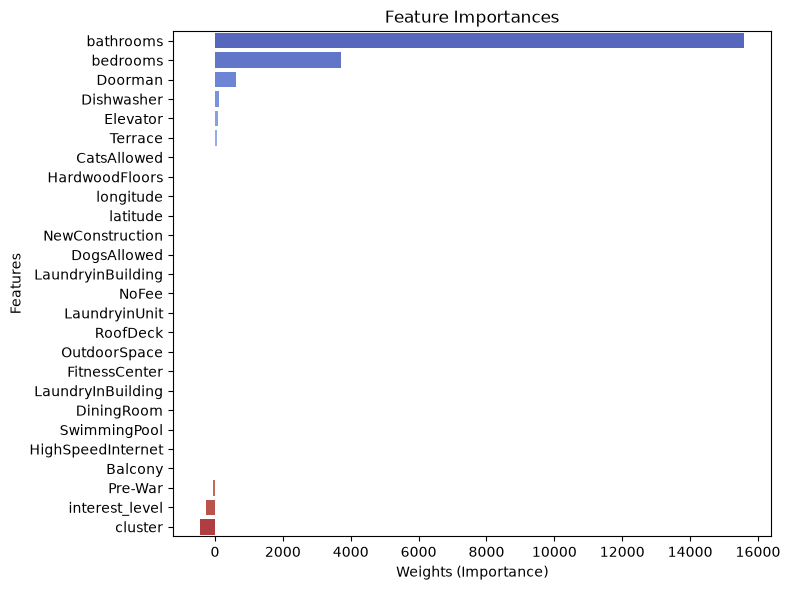

In [20]:
plt.figure(figsize=(8, 6))
sns.barplot(data=importances, x='weights', y='features', hue='features', legend=False, palette='coolwarm')

plt.xlabel('Weights (Importance)')
plt.ylabel('Features')
plt.title("Feature Importances")
plt.tight_layout()
plt.show()

### Comparing to the scikit-learn KMeans algorithm.

In [21]:
%%time
skmeans = KMeans(n_clusters=30)
skmeans.fit(X_train_ll)

CPU times: user 1.38 s, sys: 11.9 ms, total: 1.39 s
Wall time: 103 ms


,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",30
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",None
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](30, 2)

In [22]:
%%time
train_pred_sk = skmeans.predict(X_train_ll)
test_pred_sk = skmeans.predict(X_test_ll)

sil_train = silhouette_score(X_train_ll, train_pred_sk)
sil_test = silhouette_score(X_test_ll, test_pred_sk)
dist_train = sum(np.min(cdist(X_train_ll, skmeans.cluster_centers_, 'euclidean'), axis=1)**2) / X_train_ll.shape[0]
dist_test = sum(np.min(cdist(X_test_ll, skmeans.cluster_centers_, 'euclidean'), axis=1)**2) / X_test_ll.shape[0]
results.loc[len(results)] = ['SklearnKMeans', sil_train, sil_test, dist_train, dist_test]

print("Silhouette Score:")
print(f"train: {sil_train}")
print(f"test: {sil_test}")
print("\nDistortion:")
print(f"train: {dist_train}")
print(f"test: {dist_test}")

Silhouette Score:
train: 0.44865769579426784
test: 0.4444049802862171

Distortion:
train: 0.00012988671673195795
test: 0.0005588668393741869
CPU times: user 50.8 s, sys: 51.9 s, total: 1min 42s
Wall time: 13 s


#### Comparison

In [23]:
re_results = results.melt(
    id_vars='model',
    value_vars = ['Silhouette/train', 	'Silhouette/test', 	'Distortion/train', 	'Distortion/test'],
    var_name = 'metrics',
    value_name = 'score',
)

distortion = re_results.loc[re_results['metrics'].isin(['Distortion/train', 'Distortion/test'])]
silhouette = re_results.loc[re_results['metrics'].isin(['Silhouette/train', 'Silhouette/test'])]

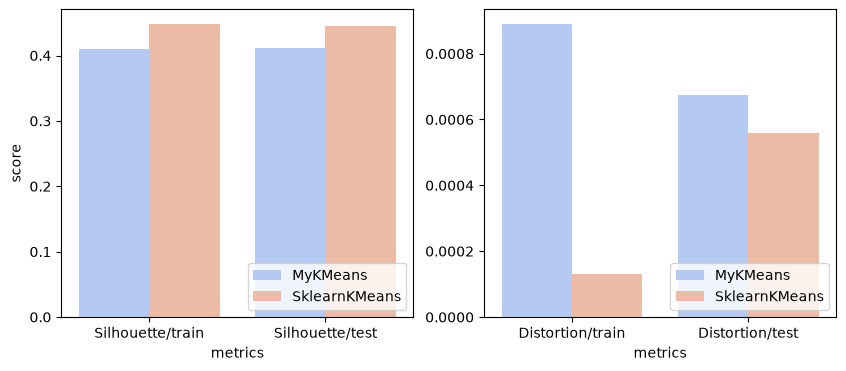

<Figure size 600x600 with 0 Axes>

In [24]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))
plt.figure(figsize=(6, 6))
sns.barplot(data=silhouette, x='metrics', y='score', hue='model', legend=True, palette='coolwarm', ax=axes[0])
sns.barplot(data=distortion, x='metrics', y='score', hue='model', legend=True, palette='coolwarm', ax=axes[1])

axes[0].legend(loc='lower right')
axes[1].legend(loc='lower right')
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

Overall the results are very similar, except Distortion on train dataset. Scikit-Learn K-Means has slightly better results anyway.

# <small> Repeating all the steps again, but with DBSCAN</small>

I wrote the model using pure python and numpy but the efficiency was horrible because of having to iterate through all the items in a list when finding the neighbors, so I had to use sklearn.neighbors.KDTree to make the model practical.

### Training the model

In [25]:
%%time
dsb = MyDBSCAN(eps=0.004, min_samples=17)
dsb.fit(X_train_ll)
print(f"Neighborhoods found: {len(np.unique(dsb.labels_))}")

Neighborhoods found: 24
CPU times: user 46.7 s, sys: 221 ms, total: 46.9 s
Wall time: 47 s


### Silhouette score

Distortion can't be calculated since there's no cluter centers

In [26]:
%%time
train_labels = dsb.fit_predict(X_train_ll)
test_labels = dsb.fit_predict(X_test_ll)

sil_train = silhouette_score(X_train_ll, train_labels)
sil_test = silhouette_score(X_test_ll, test_labels)
results.loc[len(results)] = ['MyDSBCAN', sil_train, sil_test, np.nan, np.nan]

print("Silhouette Score:")
print(f"train: {sil_train}")
print(f"test: {sil_test}")

Silhouette Score:
train: -0.1078124699367747
test: -0.19459213774412318
CPU times: user 1min 46s, sys: 56.4 s, total: 2min 42s
Wall time: 1min 8s


### Visualizing the results

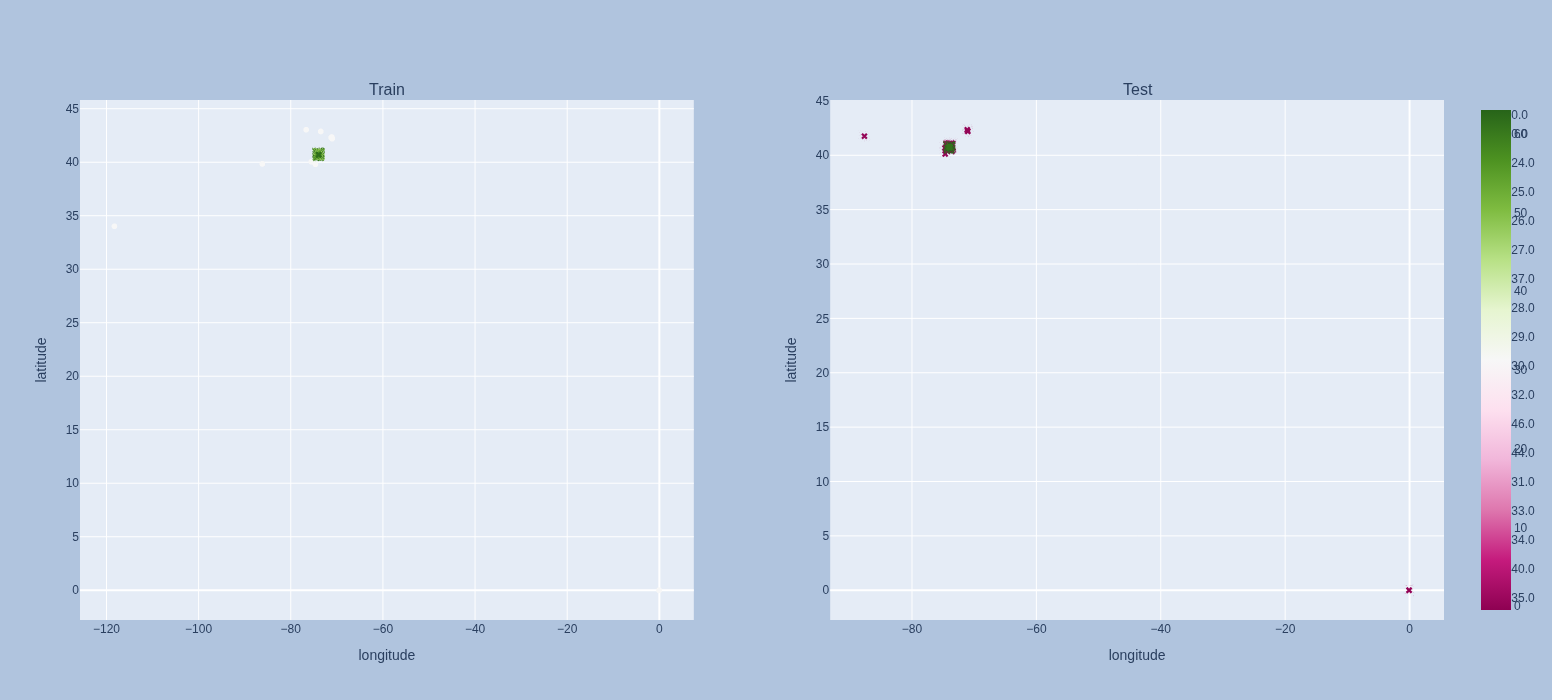

In [27]:
fig = make_subplots(subplot_titles=("Train", "Test"), rows=1, cols=2, specs=[[{"type": "scatter"}, {"type": "scatter"}]])
fig1 = px.scatter(X_train_ll, x='longitude', y='latitude', color=train_labels, symbol=train_labels)
fig2 = px.scatter(X_test_ll, x='longitude', y='latitude', color=test_labels, symbol=test_labels)

for i in [1, 2]:
  fig.update_xaxes(title_text="longitude", row = 1, col = i)
  fig.update_yaxes(title_text="latitude", row = 1, col = i)

for trace in fig1.data:
  fig.add_trace(trace, row=1, col=1)
for trace in fig2.data:
  fig.add_trace(trace, row=1, col=2)

fig.update_layout(
  width=1400,
  height=700,
  paper_bgcolor="LightSteelBlue")

fig.show()

### Adding the label of the cluster as a feature in the Lasso Regression with MinMaxScaller.

In [28]:
%%time
X_train.drop(['cluster'], axis=1, inplace=True)
X_test.drop(['cluster'], axis=1, inplace=True)

X_train['cluster'] = train_labels
X_test['cluster'] = test_labels

minmax = MinMaxScaler()
X_train_mnx = minmax.fit_transform(X_train)
X_test_mnx = minmax.transform(X_test)

CPU times: user 9.19 ms, sys: 1.11 ms, total: 10.3 ms
Wall time: 9.8 ms


Lasso

In [29]:
%%time
l1 = Lasso(random_state=42)
l1.fit(X_train_mnx, y_train)

CPU times: user 990 ms, sys: 0 ns, total: 990 ms
Wall time: 73.7 ms


,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"alpha alpha: float, default=1.0Constant that multiplies the L1 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Lasso` object is not advised.Instead, you should use the :class:`LinearRegression` object.",1.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.",False
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=1000The maximum number of iterations.",1000
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary <warm_start>`.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'
Name,Type,Value


### Feature importance as the feature weight from the Lasso

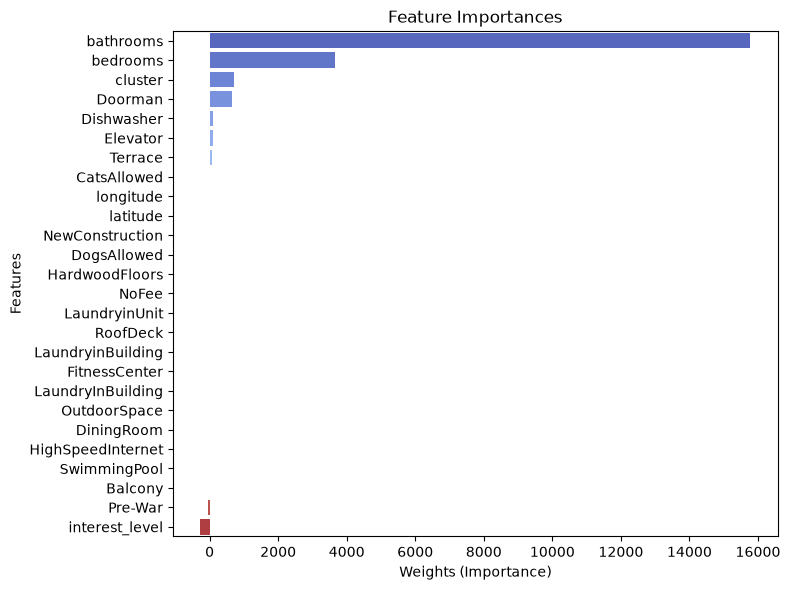

In [30]:
importances = pd.DataFrame({'features':X_train.columns, 'weights':np.array(l1.coef_)})
importances.sort_values(by='weights', ascending=False, inplace=True)

plt.figure(figsize=(8, 6))
sns.barplot(data=importances, x='weights', y='features', hue='features', legend=False, palette='coolwarm')

plt.xlabel('Weights (Importance)')
plt.ylabel('Features')
plt.title("Feature Importances")
plt.tight_layout()
plt.show()

I think it's not so bad since the cluster feature is in the top 3 most imortant features.

### Comparing to the scikit-learn DBSCAN algorithm.

In [31]:
%%time
skdbs = DBSCAN(eps=0.004, min_samples=17)
skdbs.fit(X_train_ll)
print(f"Neighborhoods found: {len(np.unique(dsb.labels_))}")

Neighborhoods found: 18
CPU times: user 382 ms, sys: 37.3 ms, total: 419 ms
Wall time: 420 ms


In [32]:
%%time
train_pred_sk = skdbs.fit_predict(X_train_ll)
test_pred_sk = skdbs.fit_predict(X_test_ll)

sil_train = silhouette_score(X_train_ll, train_pred_sk)
sil_test = silhouette_score(X_test_ll, test_pred_sk)
results.loc[len(results)] = ['SklearnDBSCAN', sil_train, sil_test, np.nan, np.nan]

print("Silhouette Score:")
print(f"train: {sil_train}")
print(f"test: {sil_test}")

Silhouette Score:
train: -0.1078124699367747
test: -0.19459213774412318
CPU times: user 51.4 s, sys: 50.6 s, total: 1min 42s
Wall time: 14.9 s


Well, also scikit-learn's DBSCAN get's a negative score

In [33]:
re_results = results[2:].melt(
    id_vars='model',
    value_vars = ['Silhouette/train', 	'Silhouette/test', 	'Distortion/train', 	'Distortion/test'],
    var_name = 'metrics',
    value_name = 'score',
)

distortion = re_results.loc[re_results['metrics'].isin(['Distortion/train', 'Distortion/test'])]
silhouette = re_results.loc[re_results['metrics'].isin(['Silhouette/train', 'Silhouette/test'])]

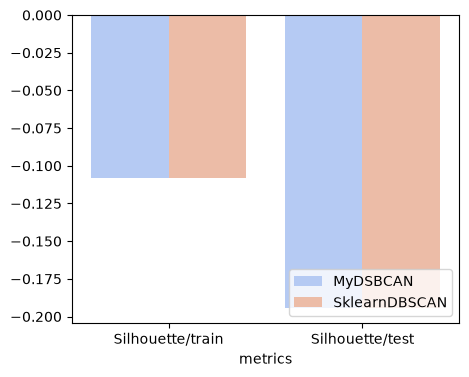

<Figure size 600x600 with 0 Axes>

In [34]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(5, 4))
plt.figure(figsize=(6, 6))
sns.barplot(data=silhouette, x='metrics', y='score', hue='model', legend=True, palette='coolwarm', ax=ax)

ax.legend(loc='lower right')
ax.legend(loc='lower right')
ax.set_ylabel("")
plt.tight_layout()
plt.show()

Well, even though scores are negative we somehow the exact score with both models.

# <small>All the same for AgglomerativeClustering</small>
<h4>But we're gonna import it from sklearn this time.</h4>

In [35]:
%%time
ac = AgglomerativeClustering(n_clusters=30).fit(X_train_ll)

CPU times: user 25.4 s, sys: 2 s, total: 27.4 s
Wall time: 27.5 s


### Solhouette score

In [36]:
%%time
train_labels = ac.fit_predict(X_train_ll)
test_labels = ac.fit_predict(X_test_ll)

sil_train = silhouette_score(X_train_ll, train_labels)
sil_test = silhouette_score(X_test_ll, test_labels)
results.loc[len(results)] = ['AgglomerativeClustering', sil_train, sil_test, np.nan, np.nan]

print("Silhouette Score:")
print(f"train: {sil_train}")
print(f"test: {sil_test}")

Silhouette Score:
train: 0.43799930891462246
test: 0.44156398333011715
CPU times: user 1min 16s, sys: 55 s, total: 2min 11s
Wall time: 40.8 s


Actually a decent score!

### Visualizing the results

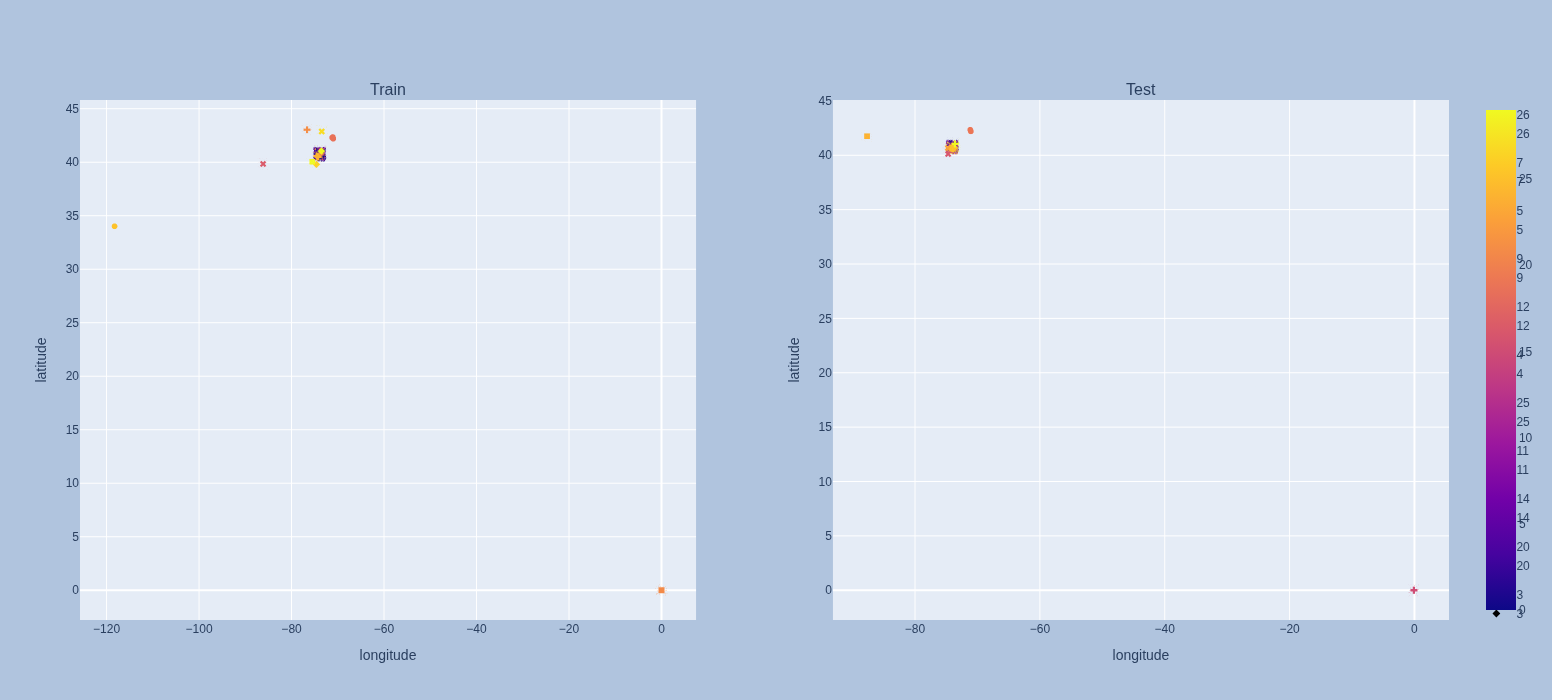

In [37]:
fig = make_subplots(subplot_titles=("Train", "Test"), rows=1, cols=2, specs=[[{"type": "scatter"}, {"type": "scatter"}]])
fig1 = px.scatter(X_train_ll, x='longitude', y='latitude', color=train_labels, symbol=train_labels)
fig2 = px.scatter(X_test_ll, x='longitude', y='latitude', color=test_labels, symbol=test_labels)

for i in [1, 2]:
  fig.update_xaxes(title_text="longitude", row = 1, col = i)
  fig.update_yaxes(title_text="latitude", row = 1, col = i)

for trace in fig1.data:
  fig.add_trace(trace, row=1, col=1)
for trace in fig2.data:
  fig.add_trace(trace, row=1, col=2)

fig.update_layout(
  width=1400,
  height=700,
  paper_bgcolor="LightSteelBlue")

fig.show()

Now we're talking

### Adding the label of the cluster as a feature in the Lasso Regression with MinMaxScaller.

In [38]:
%%time
X_train.drop(['cluster'], axis=1, inplace=True)
X_test.drop(['cluster'], axis=1, inplace=True)

X_train['cluster'] = train_labels
X_test['cluster'] = test_labels

minmax = MinMaxScaler()
X_train_mnx = minmax.fit_transform(X_train)
X_test_mnx = minmax.transform(X_test)

CPU times: user 11 ms, sys: 206 μs, total: 11.2 ms
Wall time: 12.2 ms


Lasso

In [39]:
%%time
l1 = Lasso(random_state=42)
l1.fit(X_train_mnx, y_train)

CPU times: user 723 ms, sys: 0 ns, total: 723 ms
Wall time: 61.1 ms


,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"alpha alpha: float, default=1.0Constant that multiplies the L1 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Lasso` object is not advised.Instead, you should use the :class:`LinearRegression` object.",1.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.",False
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=1000The maximum number of iterations.",1000
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary <warm_start>`.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'
Name,Type,Value


### Visualizing the feature importances

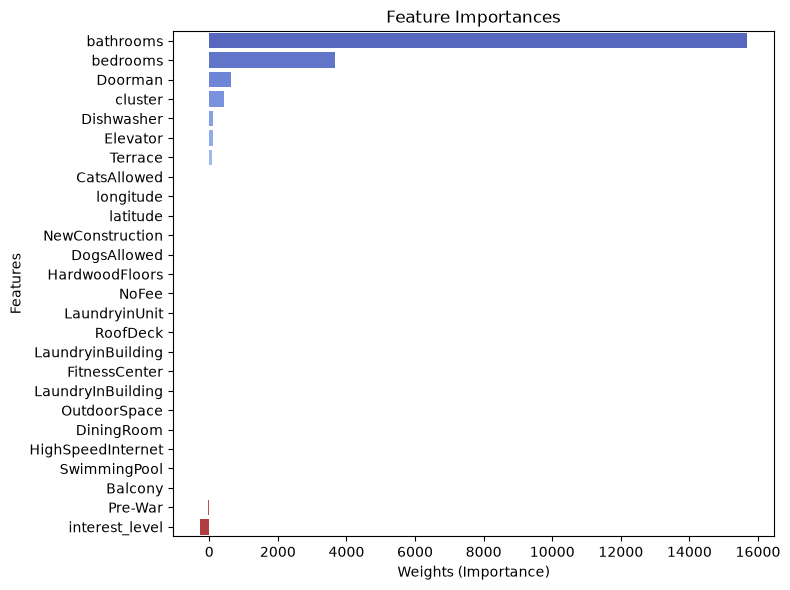

In [40]:
importances = pd.DataFrame({'features':X_train.columns, 'weights':np.array(l1.coef_)})
importances.sort_values(by='weights', ascending=False, inplace=True)

plt.figure(figsize=(8, 6))
sns.barplot(data=importances, x='weights', y='features', hue='features', legend=False, palette='coolwarm')

plt.xlabel('Weights (Importance)')
plt.ylabel('Features')
plt.title("Feature Importances")
plt.tight_layout()
plt.show()

Not bad, very similar to the last time

<h3>We don't have to compare this model to any "sklearn" model because it's the scikit learn model itself. But we still can compare it to the other models</h3>

In [41]:
results

,model,Silhouette/train,Silhouette/test,Distortion/train,Distortion/test
0,MyKMeans,0.410196,0.412032,0.000891,0.000676
1,SklearnKMeans,0.448658,0.444405,0.000130,0.000559
2,MyDSBCAN,-0.107812,-0.194592,NaN,NaN
3,SklearnDBSCAN,-0.107812,-0.194592,NaN,NaN
4,AgglomerativeClustering,0.437999,0.441564,NaN,NaN


# <small>All the same for the Gaussian Mixture algorithm.</small>

In [42]:
%%time
gmm = GaussianMixture(n_components=9, random_state=42)
gmm.fit(X_train_ll)

CPU times: user 3.13 s, sys: 7.99 ms, total: 3.14 s
Wall time: 821 ms


,"n_components n_components: int, default=1The number of mixture components.",9
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to the method chosen to initialize theparameters (see `init_params`).In addition, it controls the generation of random samples from thefitted distribution (see the method `sample`).Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"covariance_type covariance_type: {'full', 'tied', 'diag', 'spherical'}, default='full'String describing the type of covariance parameters to use.Must be one of:- 'full': each component has its own general covariance matrix.- 'tied': all components share the same general covariance matrix.- 'diag': each component has its own diagonal covariance matrix.- 'spherical': each component has its own single variance.For an example of using `covariance_type`, refer to:ref:`sphx_glr_auto_examples_mixture_plot_gmm_selection.py`.",'full'
,"tol tol: float, default=1e-3The convergence threshold. EM iterations will stop when thelower bound average gain is below this threshold.",0.001
,"reg_covar reg_covar: float, default=1e-6Non-negative regularization added to the diagonal of covariance.Allows to assure that the covariance matrices are all positive.",1e-06
,"max_iter max_iter: int, default=100The number of EM iterations to perform.",100
,"n_init n_init: int, default=1The number of initializations to perform. The best results are kept.",1
,"init_params init_params: {'kmeans', 'k-means++', 'random', 'random_from_data'}, default='kmeans'The method used to initialize the weights, the means and theprecisions.String must be one of:- 'kmeans' : responsibilities are initialized using kmeans.- 'k-means++' : use the k-means++ method to initialize.- 'random' : responsibilities are initialized randomly.- 'random_from_data' : initial means are randomly selected data points... versionchanged:: v1.1 `init_params` now accepts 'random_from_data' and 'k-means++' as initialization methods.",'kmeans'
,"weights_init weights_init: array-like of shape (n_components, ), default=NoneThe user-provided initial weights.If it is None, weights are initialized using the `init_params` method.",None
,"means_init means_init: array-like of shape (n_components, n_features), default=NoneThe user-provided initial means,If it is None, means are initialized using the `init_params` method.",None
,"precisions_init precisions_init: array-like, default=NoneThe user-provided initial precisions (inverse of the covariancematrices).If it is None, precisions are initialized using the 'init_params'method.The shape depends on 'covariance_type':: (n_components,) if 'spherical', (n_features, n_features) if 'tied', (n_components, n_features) if 'diag', (n_components, n_features, n_features) if 'full'",None


### Silhouette

In [43]:
%%time
train_labels = gmm.predict(X_train_ll)
test_labels = gmm.predict(X_test_ll)

sil_train = silhouette_score(X_train_ll, train_labels)
sil_test = silhouette_score(X_test_ll, test_labels)
results.loc[len(results)] = ['GaussianMixture', sil_train, sil_test, np.nan, np.nan]

print("Silhouette Score:")
print(f"train: {sil_train}")
print(f"test: {sil_test}")

Silhouette Score:
train: 0.2325713755173371
test: 0.23722766926295208
CPU times: user 50.3 s, sys: 51.7 s, total: 1min 42s
Wall time: 12.7 s


### Vizualize the clusters

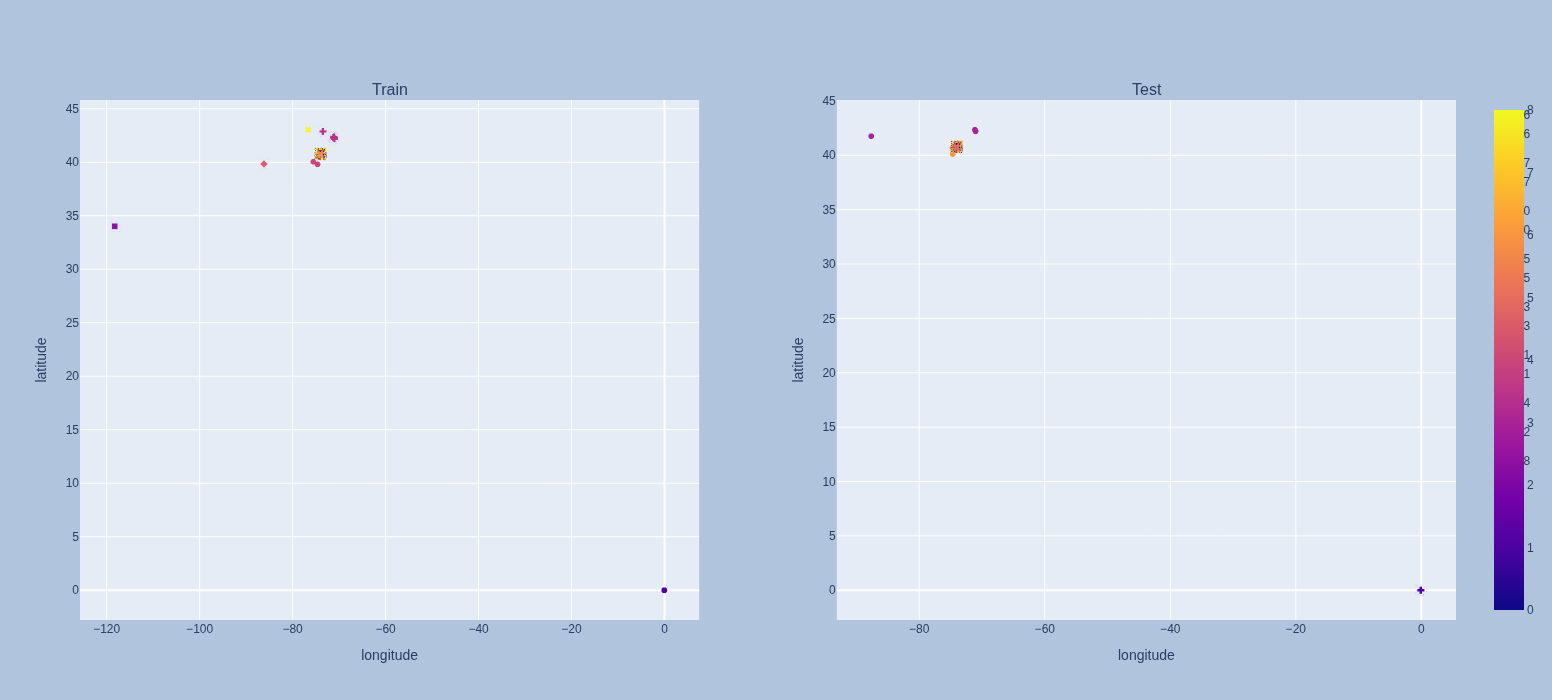

In [44]:
fig = make_subplots(subplot_titles=("Train", "Test"), rows=1, cols=2, specs=[[{"type": "scatter"}, {"type": "scatter"}]])
fig1 = px.scatter(X_train_ll, x='longitude', y='latitude', color=train_labels, symbol=train_labels)
fig2 = px.scatter(X_test_ll, x='longitude', y='latitude', color=test_labels, symbol=test_labels)

for i in [1, 2]:
  fig.update_xaxes(title_text="longitude", row = 1, col = i)
  fig.update_yaxes(title_text="latitude", row = 1, col = i)

for trace in fig1.data:
  fig.add_trace(trace, row=1, col=1)
for trace in fig2.data:
  fig.add_trace(trace, row=1, col=2)

fig.update_layout(
  width=1400,
  height=700,
  paper_bgcolor="LightSteelBlue")

fig.show()

### Adding the label of the cluster as a feature in the Lasso Regression with MinMaxScaller.

In [45]:
%%time
X_train.drop(['cluster'], axis=1, inplace=True)
X_test.drop(['cluster'], axis=1, inplace=True)

X_train['cluster'] = train_labels
X_test['cluster'] = test_labels

minmax = MinMaxScaler()
X_train_mnx = minmax.fit_transform(X_train)
X_test_mnx = minmax.transform(X_test)

CPU times: user 9.51 ms, sys: 313 μs, total: 9.82 ms
Wall time: 9.23 ms


In [46]:
%%time
l1 = Lasso(random_state=42)
l1.fit(X_train_mnx, y_train)

CPU times: user 685 ms, sys: 1.12 ms, total: 686 ms
Wall time: 52.3 ms


,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"alpha alpha: float, default=1.0Constant that multiplies the L1 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Lasso` object is not advised.Instead, you should use the :class:`LinearRegression` object.",1.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.",False
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=1000The maximum number of iterations.",1000
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary <warm_start>`.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'
Name,Type,Value


### Visualizing the feature importances

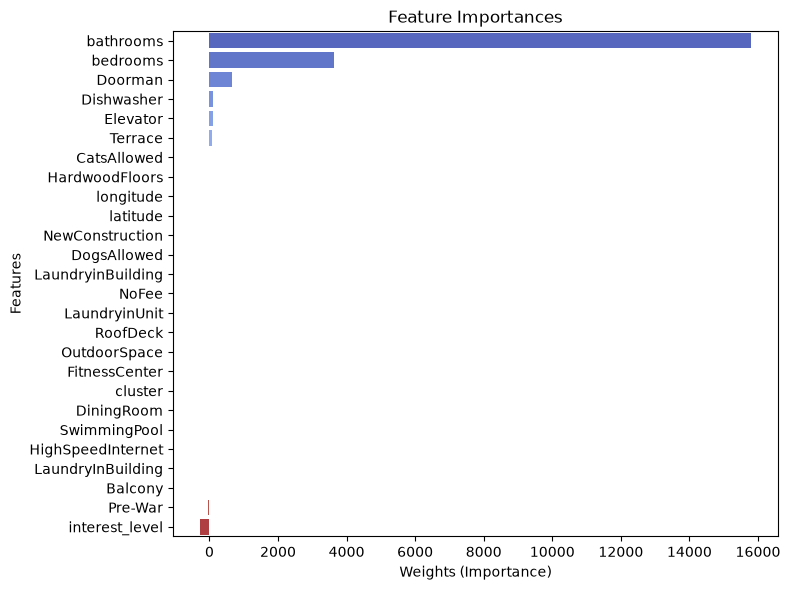

In [47]:
importances = pd.DataFrame({'features':X_train.columns, 'weights':np.array(l1.coef_)})
importances.sort_values(by='weights', ascending=False, inplace=True)

plt.figure(figsize=(8, 6))
sns.barplot(data=importances, x='weights', y='features', hue='features', legend=False, palette='coolwarm')

plt.xlabel('Weights (Importance)')
plt.ylabel('Features')
plt.title("Feature Importances")
plt.tight_layout()
plt.show()

This time our 'cluster' feature don't affect anything at all

<h3>All the metric scores</h3>

In [48]:
results

,model,Silhouette/train,Silhouette/test,Distortion/train,Distortion/test
0,MyKMeans,0.410196,0.412032,0.000891,0.000676
1,SklearnKMeans,0.448658,0.444405,0.000130,0.000559
2,MyDSBCAN,-0.107812,-0.194592,NaN,NaN
3,SklearnDBSCAN,-0.107812,-0.194592,NaN,NaN
4,AgglomerativeClustering,0.437999,0.441564,NaN,NaN
5,GaussianMixture,0.232571,0.237228,NaN,NaN


# <small>Let's try all these algorithms by clustering diffirent features - bedrooms, bathrooms and interest_level. Also measure them.</small>

### Create new dataset with features 'bedrooms', 'bathrooms', 'interest_level'

In [49]:
X_train_bbn, X_test_bbn, _, _ = train_test_split(X[['bedrooms', 'bathrooms', 'interest_level']], y, test_size=0.3, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

#### Save the metrics beforehand

In [50]:
finals = pd.DataFrame(columns=['algorithm', 'time', 'Silhouette/train', 'Silhouette/test', 'Lasso R2'])
has_predict = ['KMeans', 'GaussianMixture']

def measure(model):
  #fit
  start = time.time()
  model.fit(X_train_bbn)
  end = time.time()
  timeres = end-start

  #Silhouette
  if model.__class__.__name__ in has_predict:
    train_labels = model.predict(X_train_bbn)
    test_labels = model.predict(X_test_bbn)
  else:
    train_labels = model.fit_predict(X_train_bbn)
    test_labels = model.fit_predict(X_test_bbn)

  sil_train = silhouette_score(X_train_bbn, train_labels)
  sil_test = silhouette_score(X_test_bbn, test_labels)

  #Lasso
  if 'cluster' in X_train.columns:
    X_train.drop(['cluster'], axis=1, inplace=True)
    X_test.drop(['cluster'], axis=1, inplace=True)

  X_train['cluster'] = train_labels
  X_test['cluster'] = test_labels

  minmax = MinMaxScaler()
  X_train_mnx = minmax.fit_transform(X_train)
  X_test_mnx = minmax.transform(X_test)

  l1 = Lasso(random_state=42)
  l1.fit(X_train_mnx, y_train)
  score = l1.score(X_test_mnx, y_test)

  #Fill the dataframe
  finals.loc[len(finals)] = [model.__class__.__name__, timeres, sil_train, sil_test, score]

### Gathering all the models

In [51]:
finkmeans = KMeans(n_clusters=30)
findbs = DBSCAN(eps=0.004, min_samples=17)
finac = AgglomerativeClustering(n_clusters=30)
fingm = GaussianMixture(n_components=9)

### Let's benchmark

In [52]:
%%time
measure(finkmeans)
measure(findbs)
measure(finac)
measure(fingm)
finals

CPU times: user 3min 52s, sys: 3min 24s, total: 7min 17s
Wall time: 1min 16s


,algorithm,time,Silhouette/train,Silhouette/test,Lasso R2
0,KMeans,0.120701,0.955320,0.960352,0.557093
1,DBSCAN,1.475771,0.990562,0.983371,0.552074
2,AgglomerativeClustering,12.073333,0.961686,0.966415,0.552075
3,GaussianMixture,0.268493,0.673575,0.683782,0.559856


<h3>Review</h3>
<h4>Well, let's start with time, we can see KMeans and GaussianMixture's are fast. Lasso model's accuracy scores are basically the same, because if you paid attention to my earlier examinations the 'cluster' feature was not that important in the feature importances graph. Tho I wonder how Silhouette scores are really high, it maybe because in those 3 features we really have around 30 or even more clusters.</h4>
<hr>
<h3>Complexity of the models</h3>

<h4>KMeans - Very Fast - It's easy and simple, first assigns the centroids to random points then moves them to the mean/average of the points inside the cluster.</h4>
<hr>
<h4>DBSCAN - Moderate - It's great for finding a high density clusters while ignoring outliers or low density spaces.</h4>
<hr>
<h4>AgglomerativeClustering - Slow - It uses hierarchy clustering method (trees), it's good for smaller datasets but takes its time on bigger datasets.</h4>
<hr>
<h4>GaussianMixture - Moderate - It's the most flexible, it's really great for finding some particular clusters, it doesn't jump from here to there when finding clusters instead it starts with a one core point then extends it.</h4><hr>